# 03. Modelado

Este notebook entrena y compara los componentes del detector usando solo las particiones de entrenamiento y
validación. La partición de prueba se reserva para `05_evaluacion`, donde se usa una sola vez con el modelo final.

| Componente | Modelo | Dónde se entrena |
|---|---|---|
| Piso de referencia | `DummyClassifier` (estratificado y clase mayoritaria) | Aquí |
| Línea base de texto | TF-IDF de palabras (1-2 gramas) y caracteres (3-5 gramas) + regresión logística | Aquí, con `src.train` |
| Rama URL | XGBoost sobre 22 variables léxicas y el TLD de cada URL, sin resolverla | Aquí, con `src.train` |
| Rama de texto principal | DistilBERT (`distilbert-base-uncased`) ajustado en GPU | `notebooks/experimentos/06_distilbert` |
| Fusión tardía | Regresión logística calibrada sobre las salidas de las ramas (variantes V0 a V3) | Aquí, con `src.train` |

El reentrenamiento de la línea base y de la rama URL sirve además como prueba de reproducibilidad: se compara
con los artefactos publicados en Hugging Face Hub (versión v2) que usa la API. Ningún artefacto publicado se
sobrescribe.

In [1]:
# Rutas, semillas y módulos del proyecto. En Colab se monta Google Drive: el repositorio
# debe estar copiado en MyDrive/PI_G17/phishing-hibrido-g17 y los datos en MyDrive/PI_G17.
# Las variables de entorno G17_REPO y G17_BASE permiten usar otras ubicaciones.
import os
import sys
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    RAIZ_POR_DEFECTO = "/content/drive/MyDrive/PI_G17/phishing-hibrido-g17"
except ImportError:
    RAIZ_POR_DEFECTO = str(Path.cwd().parent)

RAIZ = Path(os.environ.get("G17_REPO", RAIZ_POR_DEFECTO)).resolve()
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio en {RAIZ}; defina G17_REPO")
sys.path.insert(0, str(RAIZ))

from src.utils import cargar_config, configurar_logging, detectar_entorno, fijar_semillas, ruta_datos
from src.visualizacion import aplicar_estilo, guardar_figura

CONFIG = cargar_config(RAIZ / "config.yaml")
SEMILLA = CONFIG["semilla"]
fijar_semillas(SEMILLA)
configurar_logging("WARNING")
aplicar_estilo()

ENTORNO = detectar_entorno()
BASE = ruta_datos(CONFIG, ENTORNO)
PROCESADOS = BASE / CONFIG["rutas"]["datos_procesados"]
MODELOS = BASE / CONFIG["rutas"]["modelos"]
FIGURAS = RAIZ / "results/figures/03_modelado"
METRICAS = RAIZ / "results/metrics"
FIGURAS.mkdir(parents=True, exist_ok=True)
METRICAS.mkdir(parents=True, exist_ok=True)
print(f"Entorno: {ENTORNO} | repositorio: {RAIZ} | datos: {BASE}")

Mounted at /content/drive
Entorno: colab | repositorio: /content/drive/MyDrive/PI_G17/phishing-hibrido-g17 | datos: /content/drive/MyDrive/PI_G17


In [2]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

from src import evaluate as ev
from src import train
from src.model import matriz_meta
from src.visualizacion import COLORES_CLASE, COLORES_SERIE, NOMBRES_CLASE

warnings.filterwarnings("ignore", message="IProgress not found")
CLASES = CONFIG["clases"]
REENTRENAR_BASELINE = True  # unos 7 minutos en Colab (CPU); False usa solo el modelo publicado

datos = pd.read_parquet(PROCESADOS / "emails_v1.parquet",
                        columns=["id", "grupo", "clase", "y", "split", "texto_modelo", "urls_defang"])
texto = datos["texto_modelo"].str[: CONFIG["texto"]["max_chars_baseline"]]
entrenamiento = (datos["split"] == "train").to_numpy()
validacion = (datos["split"] == "val").to_numpy()
y_val = datos.loc[validacion, "y"].to_numpy()
print(f"Entrenamiento: {entrenamiento.sum():,} | validación: {validacion.sum():,}")

Entrenamiento: 38,278 | validación: 8,203


## 1. Piso de referencia

Un clasificador que no mira el texto. Cualquier modelo útil debe superarlo con claridad.

In [3]:
resultados_val = {}
for estrategia in ("most_frequent", "stratified"):
    dummy = DummyClassifier(strategy=estrategia, random_state=SEMILLA).fit(
        np.zeros((entrenamiento.sum(), 1)), datos.loc[entrenamiento, "y"])
    prediccion = dummy.predict(np.zeros((validacion.sum(), 1)))
    resultados_val[f"dummy_{estrategia}"] = ev.metricas(y_val, prediccion)
pd.DataFrame({k: {"f1_macro": v["f1_macro"], "recall_phishing": v["recall"]["phishing"]}
              for k, v in resultados_val.items()}).T

,f1_macro,recall_phishing
dummy_most_frequent,0.1997,0.0000
dummy_stratified,0.3367,0.1956


## 2. Línea base: TF-IDF y regresión logística

Se elige C entre los valores de `config.yaml` por F1 macro en validación. La regresión logística usa pesos de
clase balanceados. Después se compara con el modelo publicado sobre la misma validación.

In [4]:
publicado_baseline = joblib.load(MODELOS / "baseline_tfidf_lr_v1.joblib")
p_baseline_val = publicado_baseline.predict_proba(texto[validacion])
resultados_val["baseline_publicado"] = ev.metricas(y_val, p_baseline_val.argmax(1))

comparacion_baseline = {"f1_val_publicado": resultados_val["baseline_publicado"]["f1_macro"]}
if REENTRENAR_BASELINE:
    inicio = time.time()
    reentrenado, busqueda = train.entrenar_baseline(datos, CONFIG)
    prediccion = reentrenado.predict(texto[validacion])
    comparacion_baseline.update({
        "c_optimo": busqueda["c_optimo"],
        "busqueda_c": busqueda["busqueda"],
        "f1_val_reentrenado": ev.metricas(y_val, prediccion)["f1_macro"],
        "coincidencia_predicciones_pct": round(100 * float((prediccion == p_baseline_val.argmax(1)).mean()), 2),
        "minutos": round((time.time() - inicio) / 60, 1),
    })
    del reentrenado
comparacion_baseline

{'f1_val_publicado': 0.9873,
 'c_optimo': 8.0,
 'busqueda_c': {0.5: {'f1_macro_val': 0.983, 'segundos': 126.1},
  2.0: {'f1_macro_val': 0.9865, 'segundos': 123.2},
  8.0: {'f1_macro_val': 0.9873, 'segundos': 113.7}},
 'f1_val_reentrenado': 0.9873,
 'coincidencia_predicciones_pct': 100.0,
 'minutos': 6.3}

El reentrenamiento elige el mismo C (8) y obtiene el mismo F1 macro en validación que el modelo publicado
(0,9873), con el 100 % de las predicciones iguales sobre los 8.203 correos. En una ejecución anterior de este mismo
notebook el resultado fue 0,9874 con una sola predicción distinta, igual que en la copia ejecutada de
`notebooks/experimentos/05_baseline`: la variación entre ejecuciones se limita al cuarto decimal y se atribuye a
diferencias numéricas del optimizador, no a los datos ni al código. La línea base es reproducible desde el
repositorio.

**Figura 12.** N-gramas con mayor coeficiente por clase en el modelo publicado. La regresión logística es
interpretable: cada coeficiente indica cuánto empuja un n-grama hacia una clase. Los n-gramas de caracteres se
muestran entre comillas.

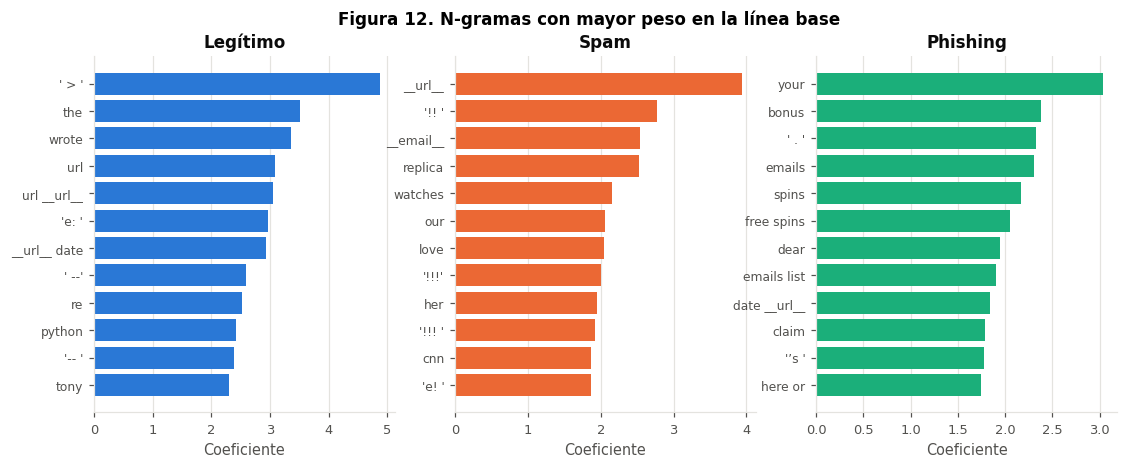

In [5]:
vocabulario = np.array(publicado_baseline.named_steps["tfidf"].get_feature_names_out())
coeficientes = publicado_baseline.named_steps["lr"].coef_
figura, ejes = plt.subplots(1, 3, figsize=(12, 4.2))
terminos_baseline = {}
for k, (eje, clase) in enumerate(zip(ejes, CLASES, strict=True)):
    mejores = np.argsort(coeficientes[k])[::-1][:12][::-1]
    # Las variables se llaman "palabras__<n-grama>" o "caracteres__<n-grama>"; los de caracteres
    # se muestran entre comillas para que se vean sus espacios.
    nombres = [n.split("__", 1)[1] if n.startswith("palabras__") else repr(n.split("__", 1)[1])
               for n in vocabulario[mejores]]
    terminos_baseline[clase] = nombres[::-1]
    eje.barh(range(len(mejores)), coeficientes[k, mejores], color=COLORES_CLASE[clase])
    eje.set_yticks(range(len(mejores)), nombres, fontsize=8)
    eje.set_title(NOMBRES_CLASE[clase])
    eje.set_xlabel("Coeficiente")
    eje.grid(axis="y", visible=False)
figura.suptitle("Figura 12. N-gramas con mayor peso en la línea base", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig12_coeficientes_baseline.png")
plt.show()

Los pesos confirman lo observado en el análisis exploratorio. En legítimo dominan rasgos de conversación en listas
de correo (el carácter de cita `>`, *wrote*, *re*); en spam, los marcadores de URL y correo, la puntuación
repetida (`!!`) y productos (*replica*, *watches*); en phishing, el tratamiento directo (*your*, *dear*) y
señuelos de premios (*bonus*, *free spins*, *claim*). Que los marcadores `__url__` y `__email__` pesen indica que
la presencia de enlaces es informativa aunque el modelo de texto no vea los dominios.

## 3. Rama URL: XGBoost sobre variables léxicas

Cada URL hereda la clase de su correo (etiqueta débil: phishing frente al resto) y ningún dominio que aparezca
en validación o prueba entra al entrenamiento, para medir generalización a dominios nuevos y no memoria de
dominios. Las URL se refangan solo en memoria para calcular las variables y nunca se resuelven.

In [6]:
categorias_tld = json.loads((MODELOS / "url_xgb_v1.meta.json").read_text())["tld_categorias"]
url_reentrenada, resumen_url = train.entrenar_url(datos, CONFIG, categorias_tld)

url_publicada = xgb.XGBClassifier()
url_publicada.load_model(MODELOS / "url_xgb_v1b_correos.json")
urls, variables = train.tabla_urls(datos, CONFIG["rama_url"]["max_urls_por_correo"])
X_urls = train.matriz_url(variables, categorias_tld)
en_validacion = (urls["split"] == "val").to_numpy()

def auc_correo(modelo):
    # AUC por correo: puntaje máximo de sus URL, phishing frente al resto (solo correos con URL)
    puntajes = pd.Series(modelo.predict_proba(X_urls[en_validacion])[:, 1], index=urls.index[en_validacion])
    por_correo = puntajes.groupby(urls.loc[en_validacion, "id"]).max()
    etiqueta = datos.set_index("id").loc[por_correo.index, "y"].eq(2).astype(int)
    return round(float(roc_auc_score(etiqueta, por_correo)), 4)

comparacion_url = {
    "urls_entrenamiento": resumen_url["urls_entrenamiento"],
    "urls_descartadas_por_dominio": resumen_url["urls_descartadas_por_dominio"],
    "mejor_iteracion_reentrenada": resumen_url["mejor_iteracion"],
    "auc_correo_val_publicada": auc_correo(url_publicada),
    "auc_correo_val_reentrenada": auc_correo(url_reentrenada),
}
comparacion_url

{'urls_entrenamiento': 10001,
 'urls_descartadas_por_dominio': 95919,
 'mejor_iteracion_reentrenada': 192,
 'auc_correo_val_publicada': 0.8756,
 'auc_correo_val_reentrenada': 0.8776}

De las URL de entrenamiento, 95.919 se descartan por compartir dominio con validación o prueba y quedan 10.001.
La rama reentrenada alcanza un AUC por correo de 0,878 en validación, equivalente al 0,876 del modelo publicado,
aunque la parada temprana se detuvo antes (192 árboles frente a 333); la causa de esa diferencia no se aisló.
Un AUC cercano a 0,88 indica que la rama URL por sí sola es un clasificador moderado: su papel es aportar una
señal independiente del texto a la fusión.

**Figura 13.** Importancia de las variables de la rama URL publicada (ganancia media en XGBoost).

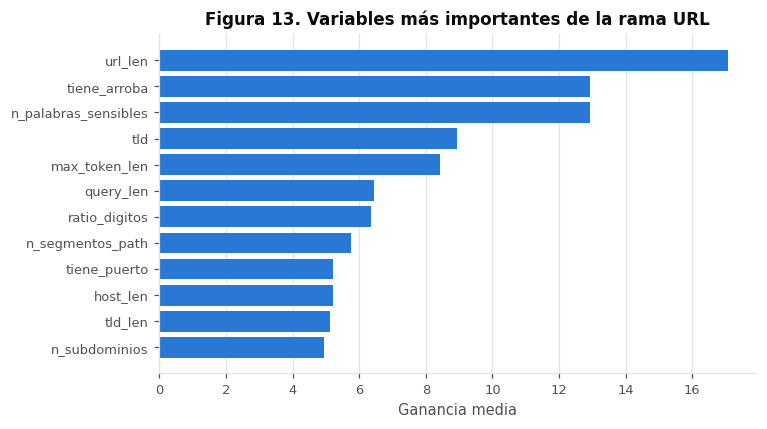

In [7]:
ganancia = pd.Series(url_publicada.get_booster().get_score(importance_type="gain")).sort_values().tail(12)
figura, eje = plt.subplots(figsize=(7, 4))
eje.barh(ganancia.index, ganancia.values, color=COLORES_SERIE[0])
eje.set_xlabel("Ganancia media")
eje.set_title("Figura 13. Variables más importantes de la rama URL")
eje.grid(axis="y", visible=False)
guardar_figura(figura, FIGURAS / "fig13_importancia_url.png")
plt.show()

Las variables que más aportan son la longitud de la URL, la presencia de `@` (técnica para ocultar el destino
real), el número de palabras sensibles (*login*, *verify*, *account*, etc.) y el dominio de primer nivel.

## 4. Rama de texto principal: DistilBERT

DistilBERT se ajustó en GPU (T4) en `notebooks/experimentos/06_distilbert`, con la configuración de la sección
`distilbert` de `config.yaml`: 3 épocas como máximo, tasa de aprendizaje 5e-5 con calentamiento lineal del 10 %,
decaimiento de pesos 0,01, lotes de 32, secuencias de 256 tokens, pesos de clase en la pérdida y parada temprana
con paciencia 1 sobre el F1 de validación. Los marcadores del pipeline se agregaron al vocabulario como tokens.
Aquí se describe la arquitectura y se leen sus probabilidades de validación.

In [8]:
configuracion_bert = json.loads((MODELOS / "distilbert_v1" / "config.json").read_text())
arquitectura = {clave: configuracion_bert.get(clave) for clave in
                ("model_type", "n_layers", "n_heads", "dim", "hidden_dim", "vocab_size",
                 "max_position_embeddings", "dropout", "attention_dropout", "seq_classif_dropout")}
try:
    from transformers import AutoModelForSequenceClassification
    from transformers.utils import logging as registro_transformers

    registro_transformers.set_verbosity_error()
    registro_transformers.disable_progress_bar()

    modelo_bert = AutoModelForSequenceClassification.from_pretrained(MODELOS / "distilbert_v1")
    arquitectura["parametros"] = int(sum(p.numel() for p in modelo_bert.parameters()))
    del modelo_bert
except ImportError:
    arquitectura["parametros"] = None
    print("transformers no está instalado: se omite el conteo de parámetros")
arquitectura

{'model_type': 'distilbert',
 'n_layers': 6,
 'n_heads': 12,
 'dim': 768,
 'hidden_dim': 3072,
 'vocab_size': 30527,
 'max_position_embeddings': 512,
 'dropout': 0.1,
 'attention_dropout': 0.1,
 'seq_classif_dropout': 0.2,
 'parametros': 66959619}

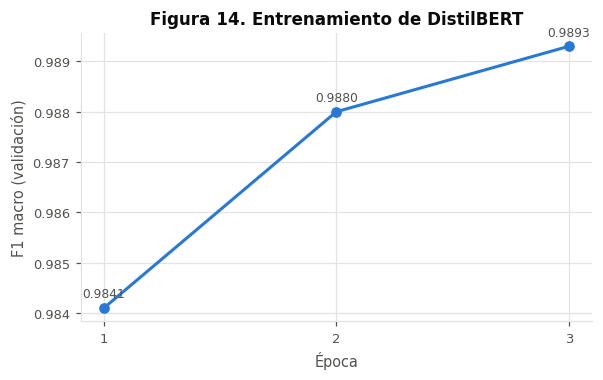

,epoca,f1_val,loss,s
0,1,0.9841,0.0034,255
1,2,0.9880,0.0009,268
2,3,0.9893,0.0003,265


In [9]:
historial = pd.DataFrame(json.loads((METRICAS / "distilbert_v1_principal.json").read_text())["historial"])
probabilidades_bert = pd.read_parquet(PROCESADOS / "text_scores_distilbert_v1.parquet")
columnas_p = ["p_legitimo", "p_spam", "p_phishing"]
bert_val = datos.loc[validacion, ["id", "y"]].merge(probabilidades_bert[["id", *columnas_p]], on="id", how="left")
if bert_val[columnas_p].isna().any().any():
    raise ValueError("Las probabilidades de DistilBERT no cubren toda la validación")
p_bert_val = bert_val[columnas_p].to_numpy()
resultados_val["distilbert"] = ev.metricas(y_val, p_bert_val.argmax(1))

figura, eje = plt.subplots(figsize=(6, 3.4))
eje.plot(historial["epoca"], historial["f1_val"], "o-", color=COLORES_SERIE[0], label="F1 macro en validación")
eje.set_xticks(historial["epoca"])
eje.set_xlabel("Época")
eje.set_ylabel("F1 macro (validación)")
eje.set_title("Figura 14. Entrenamiento de DistilBERT")
for _, fila in historial.iterrows():
    eje.annotate(f"{fila['f1_val']:.4f}", (fila["epoca"], fila["f1_val"]), textcoords="offset points",
                 xytext=(0, 7), ha="center", fontsize=8, color="#52514e")
guardar_figura(figura, FIGURAS / "fig14_entrenamiento_distilbert.png")
plt.show()
historial

El modelo tiene 66.959.619 parámetros: 6 capas de transformador con 12 cabezas de atención y dimensión 768. El
vocabulario de 30.527 tokens es el de `distilbert-base-uncased` (30.522) más los 5 marcadores del pipeline. El
F1 de validación mejoró en cada época (0,9841, 0,9880 y 0,9893), por lo que la parada temprana no se activó y
se conservó la tercera época.

## 5. Fusión tardía y calibración

El meta-clasificador recibe las log-probabilidades de las ramas y el bloque URL (puntaje máximo y medio de las
URL del correo, indicador `sin_url` y número de URL; para correos sin URL se usa el valor neutro 0,5). Se ajusta
sobre validación, que ninguna rama vio, con `train.ajustar_meta_calibrado`:

1. probabilidades fuera de pliegue (5 pliegues) para las calibraciones de Platt (`sigmoid`) e isotónica;
2. se elige la de menor puntaje de Brier;
3. el umbral de phishing es el más bajo con FPR de hasta 1 % sobre esas probabilidades (decisión D9).

Variantes: V0 solo línea base, V1 solo DistilBERT, V2 DistilBERT y URL, V3 las tres ramas. La regla de
selección, fijada antes de comparar, es el mayor recall de phishing en validación cruzada con FPR de hasta 1 %,
y el menor Brier como desempate.

In [10]:
puntajes_url = pd.read_parquet(PROCESADOS / "url_scores_v1.parquet")
ramas_val = datos.loc[validacion, ["id"]].merge(puntajes_url, on="id", how="left")

variantes = {}
for variante in ("V0", "V1", "V2", "V3"):
    X_val = matriz_meta(variante, p_bert_val, p_baseline_val, ramas_val)
    _, umbral, resumen = train.ajustar_meta_calibrado(X_val, y_val, SEMILLA, CONFIG["fusion"]["fpr_maximo_validacion"])
    variantes[variante] = resumen
tabla_variantes = pd.DataFrame({
    v: {"calibracion": r["calibracion"], "umbral": round(r["umbral"], 5),
        "recall_phishing": r["val_cv"]["recall"]["phishing"], "fpr_phishing": r["val_cv"]["fpr_phishing"],
        "f1_macro": r["val_cv"]["f1_macro"], "brier": r["brier_val_cv"], "ece_phishing": r["ece_phishing_val_cv"]}
    for v, r in variantes.items()}).T
elegida = max(variantes, key=lambda v: (variantes[v]["val_cv"]["recall"]["phishing"], -variantes[v]["brier_val_cv"]))
resultados_val["fusion_" + elegida] = variantes[elegida]["val_cv"]
print("Variante elegida:", elegida)
tabla_variantes

Variante elegida: V3


,calibracion,umbral,recall_phishing,fpr_phishing,f1_macro,brier,ece_phishing
V0,isotonic,0.17181,0.9872,0.01,0.9835,0.02259,0.01216
V1,isotonic,0.08202,0.9946,0.01,0.9865,0.01519,0.00253
V2,isotonic,0.07074,0.9953,0.01,0.9861,0.01405,0.00197
V3,isotonic,0.03899,0.996,0.0088,0.9879,0.01168,0.00631


In [11]:
publicado_fusion = json.loads((METRICAS / "fusion_v1.json").read_text())["principal"]
comparacion_fusion = {
    "elegida_ahora": elegida,
    "elegida_publicada": publicado_fusion["elegida"],
    "umbral_ahora": round(variantes[elegida]["umbral"], 5),
    "umbral_publicado": publicado_fusion[publicado_fusion["elegida"]]["umbral_fpr1"],
    "calibracion_ahora": variantes[elegida]["calibracion"],
    "calibracion_publicada": publicado_fusion[publicado_fusion["elegida"]]["calibracion"],
}
comparacion_fusion

{'elegida_ahora': 'V3',
 'elegida_publicada': 'V3',
 'umbral_ahora': 0.03899,
 'umbral_publicado': 0.03899,
 'calibracion_ahora': 'isotonic',
 'calibracion_publicada': 'isotonic'}

El ajuste desde el repositorio reproduce exactamente la fusión publicada: variante V3, calibración isotónica y
umbral 0,03899. V3 obtiene el mayor recall de phishing en validación cruzada (0,9960 con FPR de 0,88 %) y el
menor puntaje de Brier (0,0117). DistilBERT solo (V1) tiene el menor error de calibración (ECE 0,0025 frente a
0,0063), pero menor recall con la misma restricción de FPR.

**Figura 15.** Recall de phishing con FPR de hasta 1 % y puntaje de Brier por variante de fusión, en validación
cruzada.

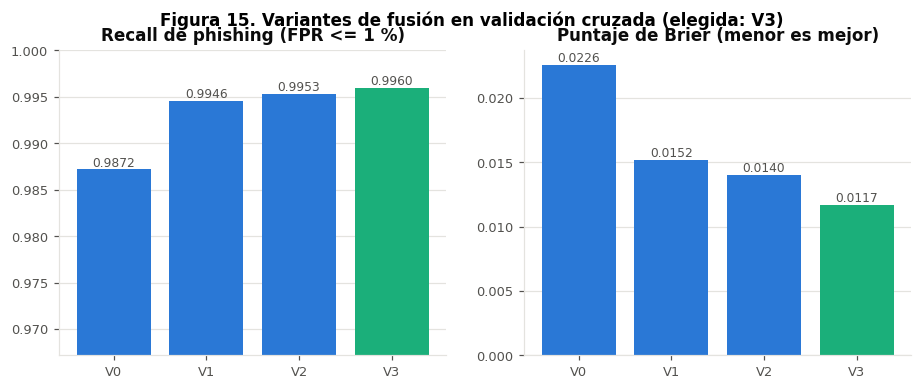

In [12]:
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(10, 3.6))
nombres = list(tabla_variantes.index)
colores = [COLORES_SERIE[2] if v == elegida else COLORES_SERIE[0] for v in nombres]
eje_a.bar(nombres, tabla_variantes["recall_phishing"].astype(float), color=colores)
eje_a.set_ylim(max(0.0, tabla_variantes["recall_phishing"].astype(float).min() - 0.02), 1.0)
eje_a.set_title("Recall de phishing (FPR <= 1 %)")
eje_b.bar(nombres, tabla_variantes["brier"].astype(float), color=colores)
eje_b.set_title("Puntaje de Brier (menor es mejor)")
for eje, columna, formato in ((eje_a, "recall_phishing", "{:.4f}"), (eje_b, "brier", "{:.4f}")):
    for x, valor in enumerate(tabla_variantes[columna].astype(float)):
        eje.text(x, valor, formato.format(valor), ha="center", va="bottom", fontsize=8, color="#52514e")
    eje.grid(axis="x", visible=False)
figura.suptitle(f"Figura 15. Variantes de fusión en validación cruzada (elegida: {elegida})",
                fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig15_variantes_fusion.png")
plt.show()

## 6. Comparación en validación

**Figura 16.** F1 macro y recall de phishing en validación. La fusión se reporta con probabilidades fuera de
pliegue y su umbral por FPR; los demás modelos, con la clase más probable.

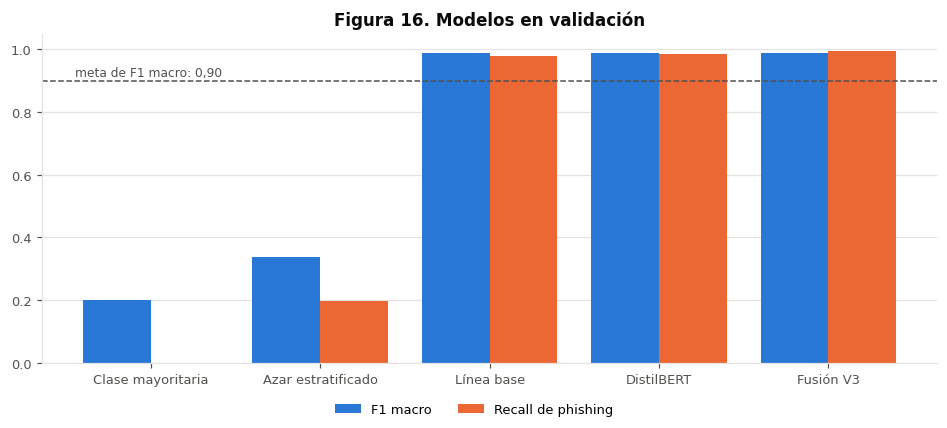

,f1_macro,recall_phishing,fpr_phishing
dummy_most_frequent,0.1997,0.0000,0.0000
dummy_stratified,0.3367,0.1956,0.1823
baseline_publicado,0.9873,0.9792,0.0043
distilbert,0.9893,0.9839,0.0043
fusion_V3,0.9879,0.9960,0.0088


In [13]:
comparacion = pd.DataFrame({
    nombre: {"f1_macro": r["f1_macro"], "recall_phishing": r["recall"]["phishing"],
             "fpr_phishing": r["fpr_phishing"]}
    for nombre, r in resultados_val.items()}).T
etiquetas = {"dummy_most_frequent": "Clase mayoritaria", "dummy_stratified": "Azar estratificado",
             "baseline_publicado": "Línea base", "distilbert": "DistilBERT"}
figura, eje = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
posiciones = np.arange(len(comparacion))
eje.bar(posiciones - 0.2, comparacion["f1_macro"], width=0.4, color=COLORES_SERIE[0], label="F1 macro")
eje.bar(posiciones + 0.2, comparacion["recall_phishing"], width=0.4, color=COLORES_SERIE[1],
        label="Recall de phishing")
eje.set_xticks(posiciones, [etiquetas.get(n, n.replace("fusion_", "Fusión ")) for n in comparacion.index])
eje.set_ylim(0, 1.05)
eje.axhline(CONFIG["metas_smart"]["f1_macro"], color="#52514e", linestyle="--", linewidth=1)
eje.text(-0.45, CONFIG["metas_smart"]["f1_macro"] + 0.015, "meta de F1 macro: 0,90", ha="left", fontsize=8,
         color="#52514e")
figura.legend(loc="outside lower center", ncols=2)
eje.set_title("Figura 16. Modelos en validación")
eje.grid(axis="x", visible=False)
guardar_figura(figura, FIGURAS / "fig16_comparacion_validacion.png")
plt.show()
comparacion

Los tres modelos superan con amplitud al piso de referencia y a la meta de F1. DistilBERT tiene el mayor F1
macro (0,9893); la fusión, el mayor recall de phishing (0,9960), a cambio de un FPR algo mayor (0,88 % frente a
0,43 %) porque su umbral se fijó para admitir hasta 1 % de falsos positivos. La comparación definitiva, con
intervalos de confianza y pruebas estadísticas, se hace sobre la partición de prueba en `05_evaluacion`.

## 7. Resumen

El diagnóstico de sobreajuste y subajuste (curvas de aprendizaje y de validación, regularización de DistilBERT y
de un modelo lineal) se hizo en la Semana 3: `notebooks/experimentos/16_diagnostico_sobreajuste` y
`results/figures/semana3/`.

In [14]:
resumen = {
    "validacion": resultados_val,
    "baseline": comparacion_baseline,
    "rama_url": comparacion_url,
    "distilbert": {"arquitectura": arquitectura, "historial": historial.to_dict(orient="records")},
    "fusion": {"variantes": variantes, "comparacion_publicado": comparacion_fusion},
    "terminos_baseline": terminos_baseline,
}
(METRICAS / "modelado_resumen.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=str),
                                                encoding="utf-8")
print(json.dumps({"baseline": comparacion_baseline, "rama_url": comparacion_url, "fusion": comparacion_fusion},
                 indent=1, ensure_ascii=False, default=str))

{
 "baseline": {
  "f1_val_publicado": 0.9873,
  "c_optimo": 8.0,
  "busqueda_c": {
   "0.5": {
    "f1_macro_val": 0.983,
    "segundos": 126.1
   },
   "2.0": {
    "f1_macro_val": 0.9865,
    "segundos": 123.2
   },
   "8.0": {
    "f1_macro_val": 0.9873,
    "segundos": 113.7
   }
  },
  "f1_val_reentrenado": 0.9873,
  "coincidencia_predicciones_pct": 100.0,
  "minutos": 6.3
 },
 "rama_url": {
  "urls_entrenamiento": 10001,
  "urls_descartadas_por_dominio": 95919,
  "mejor_iteracion_reentrenada": 192,
  "auc_correo_val_publicada": 0.8756,
  "auc_correo_val_reentrenada": 0.8776
 },
 "fusion": {
  "elegida_ahora": "V3",
  "elegida_publicada": "V3",
  "umbral_ahora": 0.03899,
  "umbral_publicado": 0.03899,
  "calibracion_ahora": "isotonic",
  "calibracion_publicada": "isotonic"
 }
}
